# Nhận dạng chữ số MNIST bằng CNN + MLP — bản PyTorch

Chuyển từ notebook Keras gốc: `Example/examples/2. CNN + MLP/1_MNIST_CNN.ipynb`.
Giữ nguyên dữ liệu, kiến trúc, hàm mất mát, optimizer, learning rate, batch size; chỉ thay framework.

**Đối chiếu Keras → PyTorch trong notebook này**

| Keras (gốc) | PyTorch (bản chuyển) |
|---|---|
| ảnh `(N, 28, 28, 1)` – channels-last | ảnh `(N, 1, 28, 28)` – PyTorch dùng **channels-first** |
| `Conv2D(64, (3,3), padding='same', activation='relu')` | `nn.Conv2d(1, 64, 3, padding=1)` + `nn.ReLU()` (PyTorch cần khai báo số kênh vào) |
| `MaxPooling2D((2,2))`, `Dropout(0.2)` | `nn.MaxPool2d(2)`, `nn.Dropout(0.2)` |
| `Flatten` → `Dense(512)` | `nn.Flatten()` → `nn.Linear(256*3*3, 512)` (phải tự tính số đặc trưng sau conv) |
| `categorical_crossentropy` + softmax, `SGD(lr=0.01)` | `nn.CrossEntropyLoss()` (logits), `torch.optim.SGD(lr=0.01)` |
| `Model(model.input, get_layer('fc2').output)` | `forward(..., return_features=True)` |
| `GlobalAveragePooling2D()(pool3)` | `feat_pool3.mean(dim=(2, 3))` |

> **Cấu hình chạy trên CPU:** bản gốc train 30 epoch (thầy ghi ~105 phút trên Core i7). Trên máy chạy bài này
> (CPU 12 nhân) mỗi epoch ~2–3 phút nên đặt `EPOCHS = 10`; có GPU/Colab thì đổi lại `EPOCHS = 30`.

# Import libraries

In [1]:
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

# Thư mục gốc bài nộp = thư mục cha gần nhất có chứa "data/"
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
DATA = ROOT / "data"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("ROOT =", ROOT, "| device =", DEVICE, "| torch", torch.__version__)

np.random.seed(2024); torch.manual_seed(2024)
num_classes = 10
EPOCHS = 10   # Keras gốc: 30 (giảm để chạy trên CPU)

ROOT = d:\SGU\deep-learning\Tuan13\BTL03_TranQuocAn_3123411009 | device = cpu | torch 2.14.0+cpu


In [2]:
def summary(model, input_size, keras_params=None):
    """Tương đương model.summary() của Keras: tên lớp, output shape, số tham số."""
    rows, hooks = [], []
    for name, m in model.named_modules():
        if len(list(m.children())) == 0 and name:
            hooks.append(m.register_forward_hook(
                lambda mod, i, o, name=name: rows.append(
                    (name, type(mod).__name__, tuple(o.shape) if torch.is_tensor(o) else "-",
                     sum(p.numel() for p in mod.parameters(recurse=False))))))
    was_training = model.training
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, *input_size, device=next(model.parameters()).device))
    model.train(was_training)
    for h in hooks:
        h.remove()
    print(f"{'Layer':<22}{'Type':<16}{'Output shape':<26}{'Param #':>12}")
    print("=" * 76)
    for n, t, s, p in rows:
        print(f"{n:<22}{t:<16}{str(s):<26}{p:>12,}")
    total = sum(p.numel() for p in model.parameters())
    print("=" * 76)
    print(f"Total params: {total:,}" + (f"   (Keras gốc: {keras_params:,})" if keras_params else ""))

def keras_init(model):
    """Khởi tạo giống mặc định Keras: kernel glorot_uniform, bias = 0
    (PyTorch mặc định dùng kaiming_uniform nên kết quả có thể lệch nhẹ nếu không làm bước này)."""
    for m in model.modules():
        if isinstance(m, (nn.Linear, nn.Conv2d)):
            nn.init.xavier_uniform_(m.weight)
            nn.init.zeros_(m.bias)
    return model

def run_epoch(model, loader, loss_fn, metric_fn=None, optimizer=None, augment=None):
    """1 epoch train (có optimizer) hoặc đánh giá (optimizer=None). Trả về (loss, metric) trung bình theo mẫu."""
    training = optimizer is not None
    model.train(training)
    tot_loss, tot_metric, n = 0.0, 0.0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            if augment is not None and training:
                xb = augment(xb)
            out = model(xb)                      # forward
            loss = loss_fn(out, yb)              # loss
            if training:
                optimizer.zero_grad()            # xoá gradient cũ
                loss.backward()                  # backpropagation
                optimizer.step()                 # cập nhật trọng số
            tot_loss += loss.item() * len(xb)
            if metric_fn is not None:
                tot_metric += metric_fn(out.detach(), yb) * len(xb)
            n += len(xb)
    return tot_loss / n, (tot_metric / n if metric_fn is not None else None)


def fit(model, train_loader, val_loader, epochs, optimizer, loss_fn, metric_fn=None, metric_name="accuracy",
        augment=None):
    """Tương đương model.fit(..., validation_data=...): in log mỗi epoch, trả về history."""
    history = {"loss": [], "val_loss": [], metric_name: [], "val_" + metric_name: []}
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_m = run_epoch(model, train_loader, loss_fn, metric_fn, optimizer, augment)
        va_loss, va_m = run_epoch(model, val_loader, loss_fn, metric_fn)
        history["loss"].append(tr_loss); history["val_loss"].append(va_loss)
        history[metric_name].append(tr_m); history["val_" + metric_name].append(va_m)
        msg = f"Epoch {ep}/{epochs} - {time.time() - t0:.0f}s - loss: {tr_loss:.4f}"
        if metric_fn is not None:
            msg += f" - {metric_name}: {tr_m:.4f}"
        msg += f" - val_loss: {va_loss:.4f}"
        if metric_fn is not None:
            msg += f" - val_{metric_name}: {va_m:.4f}"
        print(msg, flush=True)
    return history


def accuracy(out, y):
    """Độ chính xác phân loại: so argmax của logits với nhãn số nguyên."""
    return (out.argmax(1) == y).float().mean().item()


def plot_history(history, metric_name="accuracy"):
    keys = [("loss", "val_loss")] + ([(metric_name, "val_" + metric_name)] if history[metric_name][0] is not None else [])
    fig, axes = plt.subplots(1, len(keys), figsize=(6 * len(keys), 3.8))
    axes = np.atleast_1d(axes)
    for ax, (a, b) in zip(axes, keys):
        ax.plot(range(1, len(history[a]) + 1), history[a], marker="o", label="train")
        ax.plot(range(1, len(history[b]) + 1), history[b], marker="o", label="validation")
        ax.set_xlabel("epoch"); ax.set_ylabel(a); ax.grid(alpha=.3); ax.legend()
    plt.tight_layout(); plt.show()

def load_mnist():
    """Tương đương keras.datasets.mnist.load_data(): tải đúng file mnist.npz mà Keras dùng."""
    path = DATA / "mnist.npz"
    if not path.exists():
        import urllib.request
        path.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve("https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz", path)
    d = np.load(path)
    return (d["x_train"], d["y_train"]), (d["x_test"], d["y_test"])

# (1) Data

In [3]:
(x_train, y_train), (x_test, y_test) = load_mnist()
# Keras: reshape(60000, 28, 28, 1)  ->  PyTorch: (60000, 1, 28, 28)
x_train = x_train.reshape(60000, 1, 28, 28).astype("float32") / 255
x_test = x_test.reshape(10000, 1, 28, 28).astype("float32") / 255
print(x_train.shape[0], "train samples"); print(x_test.shape[0], "test samples")

train_loader = DataLoader(TensorDataset(torch.from_numpy(x_train), torch.from_numpy(y_train).long()), batch_size=128, shuffle=True)
test_loader = DataLoader(TensorDataset(torch.from_numpy(x_test), torch.from_numpy(y_test).long()), batch_size=512)

60000 train samples
10000 test samples


In [4]:
# keras.utils.to_categorical(2, num_classes=3)
F.one_hot(torch.tensor(2), num_classes=3).float()

tensor([0., 0., 1.])

# (2) Declare model

In [5]:
class MnistCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        # conv, pooling layers + dropout
        self.conv1 = nn.Conv2d(1, 64, 3, padding=1);    self.pool1 = nn.MaxPool2d(2); self.conv_dropout1 = nn.Dropout(0.2)
        self.conv2 = nn.Conv2d(64, 128, 3, padding=1);  self.pool2 = nn.MaxPool2d(2); self.conv_dropout2 = nn.Dropout(0.2)
        self.conv3 = nn.Conv2d(128, 256, 3, padding=1); self.pool3 = nn.MaxPool2d(2); self.conv_dropout3 = nn.Dropout(0.2)
        # similar to the MLP example!
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(256 * 3 * 3, 512); self.fc_dropout1 = nn.Dropout(0.2)
        self.fc2 = nn.Linear(512, 512);         self.fc_dropout2 = nn.Dropout(0.2)
        self.fc3_10ways_softmax = nn.Linear(512, num_classes)

    def forward(self, x, return_features=False):
        x = self.conv_dropout1(self.pool1(F.relu(self.conv1(x))))   # 28 -> 14
        x = self.conv_dropout2(self.pool2(F.relu(self.conv2(x))))   # 14 -> 7
        pool3 = self.pool3(F.relu(self.conv3(x)))                   # 7 -> 3
        x = self.flatten(self.conv_dropout3(pool3))
        x = self.fc_dropout1(F.relu(self.fc1(x)))
        fc2 = F.relu(self.fc2(x))
        out = self.fc3_10ways_softmax(self.fc_dropout2(fc2))
        return (fc2, pool3, out) if return_features else out


model = keras_init(MnistCNN(num_classes)).to(DEVICE)
summary(model, (1, 28, 28), keras_params=1_817_610)

Layer                 Type            Output shape                   Param #
conv1                 Conv2d          (1, 64, 28, 28)                    640
pool1                 MaxPool2d       (1, 64, 14, 14)                      0
conv_dropout1         Dropout         (1, 64, 14, 14)                      0
conv2                 Conv2d          (1, 128, 14, 14)                73,856
pool2                 MaxPool2d       (1, 128, 7, 7)                       0
conv_dropout2         Dropout         (1, 128, 7, 7)                       0
conv3                 Conv2d          (1, 256, 7, 7)                 295,168
pool3                 MaxPool2d       (1, 256, 3, 3)                       0
conv_dropout3         Dropout         (1, 256, 3, 3)                       0
flatten               Flatten         (1, 2304)                            0
fc1                   Linear          (1, 512)                     1,180,160
fc_dropout1           Dropout         (1, 512)                             0

# (3) Train defined model

Epoch 1/10 - 113s - loss: 2.0720 - accuracy: 0.3076 - val_loss: 0.9642 - val_accuracy: 0.7440


Epoch 2/10 - 115s - loss: 0.7343 - accuracy: 0.7534 - val_loss: 0.2770 - val_accuracy: 0.9181


Epoch 3/10 - 109s - loss: 0.3799 - accuracy: 0.8785 - val_loss: 0.1731 - val_accuracy: 0.9463


Epoch 4/10 - 114s - loss: 0.2656 - accuracy: 0.9154 - val_loss: 0.1319 - val_accuracy: 0.9585


Epoch 5/10 - 114s - loss: 0.2172 - accuracy: 0.9312 - val_loss: 0.1138 - val_accuracy: 0.9636


Epoch 6/10 - 113s - loss: 0.1888 - accuracy: 0.9405 - val_loss: 0.0989 - val_accuracy: 0.9684


Epoch 7/10 - 118s - loss: 0.1695 - accuracy: 0.9473 - val_loss: 0.0905 - val_accuracy: 0.9695


Epoch 8/10 - 113s - loss: 0.1540 - accuracy: 0.9516 - val_loss: 0.0808 - val_accuracy: 0.9735


Epoch 9/10 - 114s - loss: 0.1439 - accuracy: 0.9550 - val_loss: 0.0737 - val_accuracy: 0.9757


Epoch 10/10 - 113s - loss: 0.1330 - accuracy: 0.9579 - val_loss: 0.0688 - val_accuracy: 0.9766


> training time is 18.9250 minutes


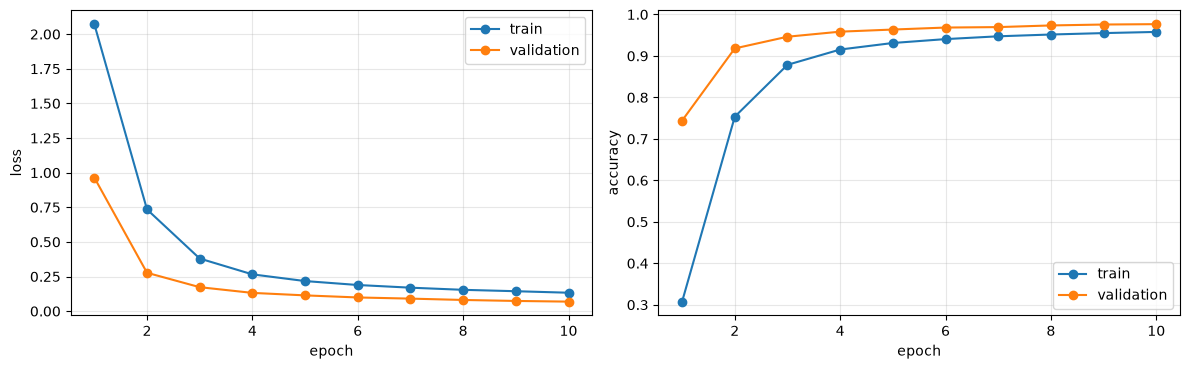

In [6]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)
starting_time = time.time()
history = fit(model, train_loader, test_loader, EPOCHS, optimizer, loss_fn, accuracy)
print("> training time is %.4f minutes" % ((time.time() - starting_time) / 60))
plot_history(history)

# (4) Evaluate trained model

In [7]:
test_loss, test_acc = run_epoch(model, test_loader, loss_fn, accuracy)
print("Test loss:", test_loss)
print("Test accuracy:", test_acc)

Test loss: 0.06878933534622192
Test accuracy: 0.9766000005722046


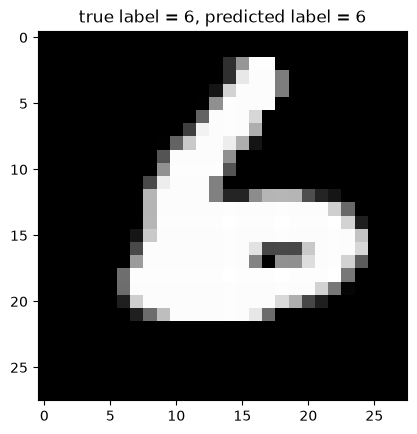

In [8]:
# select a test image randomly
model.eval()
i = np.random.choice(x_test.shape[0], size=1)[0]
with torch.no_grad():
    pred_label = model(torch.from_numpy(x_test[i:i + 1]).to(DEVICE)).argmax(1).item()
plt.imshow(x_test[i, 0], cmap="gray")
plt.title("true label = %d, predicted label = %d" % (y_test[i], pred_label)); plt.show()

### Trực quan hoá dữ liệu gốc và đặc trưng học được bằng PCA (như bản gốc)

raw: (60000, 784) | fc2: (60000, 512) | GAP(pool3): (60000, 256)


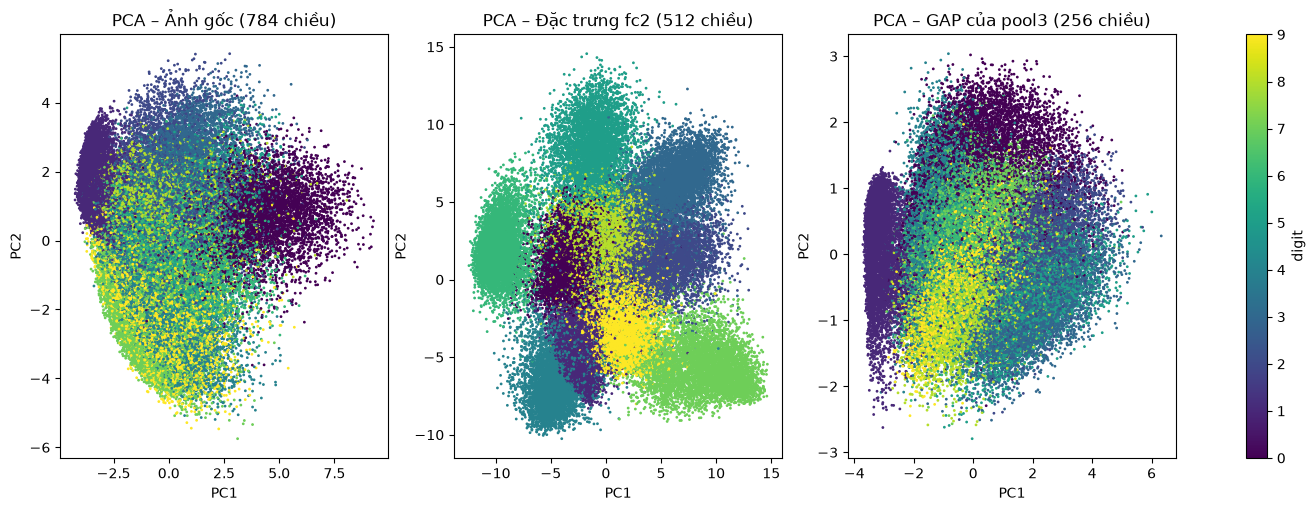

In [9]:
from sklearn.decomposition import PCA


@torch.no_grad()
def extract(x, bs=1000):
    """Lấy đặc trưng fc2 (512) và GlobalAveragePooling của pool3 (256) cho toàn bộ x."""
    model.eval()
    f_fc2, f_gap = [], []
    for k in range(0, len(x), bs):
        fc2, pool3, _ = model(torch.from_numpy(x[k:k + bs]).to(DEVICE), return_features=True)
        f_fc2.append(fc2.cpu()); f_gap.append(pool3.mean(dim=(2, 3)).cpu())   # GlobalAveragePooling2D
    return torch.cat(f_fc2).numpy(), torch.cat(f_gap).numpy()


y_feat, y2_feat = extract(x_train)
print("raw:", x_train.reshape(len(x_train), -1).shape, "| fc2:", y_feat.shape, "| GAP(pool3):", y2_feat.shape)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, (data, title) in zip(axes, [(x_train.reshape(len(x_train), -1), "Ảnh gốc (784 chiều)"),
                                     (y_feat, "Đặc trưng fc2 (512 chiều)"),
                                     (y2_feat, "GAP của pool3 (256 chiều)")]):
    pc = PCA(n_components=2).fit_transform(data)
    sc = ax.scatter(pc[:, 0], pc[:, 1], c=y_train, cmap="viridis", s=1)
    ax.set_title("PCA – " + title); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
fig.colorbar(sc, ax=axes, label="digit"); plt.show()